In [ ]:
# ============================================
# Agile Traffic Congestion Prediction
# A Continuous Learning Framework for
# Dynamic Urban Mobility
# ============================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from collections import deque
import warnings
import json
from datetime import datetime
import os

warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt

print("=" * 70)
print("Agile Traffic Congestion Prediction: A Continuous Learning Framework")
print("for Dynamic Urban Mobility")
print("=" * 70)

Agile Traffic Congestion Prediction: A Continuous Learning Framework
for Dynamic Urban Mobility


In [ ]:
class ModelVersion:
    """Track model versions for agile deployment"""
    def __init__(self, version_id, metrics, timestamp, description):
        self.version_id = version_id
        self.metrics = metrics
        self.timestamp = timestamp
        self.description = description

class AgileConfig:
    def __init__(self):
        # Continuous learning parameters
        self.retraining_threshold_mae = 5.0  # Retrain if MAE exceeds this
        self.retraining_interval = 500  # Retrain every N new samples
        self.validation_split = 0.2
        self.test_split = 0.1

        # Model architecture (can change in agile sprints)
        self.input_size = 10
        self.hidden_sizes = [128, 64, 32]
        self.output_size = 1
        self.dropout_rate = 0.2

        # Training hyperparameters (tunable per sprint)
        self.learning_rate = 0.001
        self.batch_size = 32
        self.epochs_per_sprint = 50

        # Agile/MLOps features
        self.enable_ab_testing = True
        self.enable_model_canarying = True
        self.enable_automated_retraining = True
        self.enable_experiment_tracking = True

        # Data stream simulation
        self.stream_batch_size = 100
        self.total_stream_samples = 5000

config = AgileConfig()

print(f"\n[Agile Configuration Loaded]")
print(f"  - Retraining Threshold (MAE): {config.retraining_threshold_mae}")
print(f"  - Retraining Interval: {config.retraining_interval} samples")
print(f"  - A/B Testing: {'ENABLED' if config.enable_ab_testing else 'Disabled'}")
print(f"  - Automated Retraining: {'ENABLED' if config.enable_automated_retraining else 'Disabled'}")
print(f"  - Experiment Tracking: {'ENABLED' if config.enable_experiment_tracking else 'Disabled'}")


[Agile Configuration Loaded]
  - Retraining Threshold (MAE): 5.0
  - Retraining Interval: 500 samples
  - A/B Testing: ENABLED
  - Automated Retraining: ENABLED
  - Experiment Tracking: ENABLED


In [ ]:
class AgileTrafficModel(nn.Module):
    """
    Modular model architecture that can be easily modified
    during agile sprints without breaking the pipeline
    """
    def __init__(self, config, variant='A'):
        super(AgileTrafficModel, self).__init__()
        self.config = config
        self.variant = variant
        self.version = "1.0.0"

        # Build layers dynamically (easy to modify in next sprint)
        layers = []
        prev_size = config.input_size

        for i, hidden_size in enumerate(config.hidden_sizes):
            layers.append(nn.Linear(prev_size, hidden_size))
            layers.append(nn.BatchNorm1d(hidden_size))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(config.dropout_rate))
            prev_size = hidden_size

        layers.append(nn.Linear(prev_size, config.output_size))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

    def get_version(self):
        return f"Model_{self.variant}_v{self.version}"

In [ ]:
class ContinuousLearningManager:
    """
    Manages continuous model updates, versioning, and deployment
    Implements agile MLOps practices
    """
    def __init__(self, config):
        self.config = config
        self.models = {}  # Dictionary of model versions
        self.active_model = None
        self.candidate_model = None
        self.model_performance_history = []
        self.data_buffer = deque(maxlen=config.retraining_interval * 2)
        self.samples_processed = 0

        # Initialize experiment tracking and logs
        self.experiments = []
        self.performance_log = [] # To store performance at evaluation points
        self.retraining_log = []  # To store details about retraining events


    def create_new_model(self, variant='A'):
        """Create a new model instance (for A/B testing or retraining)"""
        model = AgileTrafficModel(self.config, variant)
        # Assign a unique version based on timestamp or increment
        version_id = f"v{datetime.now().strftime('%Y%m%d%H%M%S')}_{variant}"
        model.version = version_id
        return model

    def train_model(self, model, X_train, y_train, epochs):
        """Train a given model instance"""
        model.train()
        optimizer = optim.Adam(model.parameters(), lr=self.config.learning_rate)
        criterion = nn.MSELoss() # Using MSE for training

        dataset = torch.utils.data.TensorDataset(X_train, y_train)
        dataloader = torch.utils.data.DataLoader(dataset, batch_size=self.config.batch_size, shuffle=True)

        for epoch in range(epochs):
            for batch_X, batch_y in dataloader:
                optimizer.zero_grad()
                outputs = model(batch_X).squeeze()
                loss = criterion(outputs, batch_y)
                loss.backward()
                optimizer.step()
        return model

    def evaluate_model(self, model, X, y):
        """Evaluate model performance"""
        model.eval()
        with torch.no_grad():
            predictions = model(X).numpy().flatten()
        mae = mean_absolute_error(y, predictions)
        rmse = np.sqrt(mean_squared_error(y, predictions))
        r2 = r2_score(y, predictions)
        return {'mae': mae, 'rmse': rmse, 'r2': r2}

    def should_retrain(self, current_mae):
        """Determine if model needs retraining based on performance degradation or interval"""
        if not self.config.enable_automated_retraining:
            return False, "Automated retraining is disabled."

        if current_mae > self.config.retraining_threshold_mae:
            return True, f"MAE ({current_mae:.2f}) exceeded retraining threshold ({self.config.retraining_threshold_mae:.2f})."

        if self.samples_processed >= self.config.retraining_interval and \
           self.samples_processed % self.config.retraining_interval < self.config.stream_batch_size: # Trigger once per interval
            return True, f"Retraining interval ({self.config.retraining_interval} samples) reached."

        return False, "No retraining criteria met."

    def log_experiment(self, model_version, metrics, notes=""):
        """Log experiment for tracking"""
        experiment = {
            'timestamp': datetime.now().isoformat(),
            'model_version': model_version,
            'metrics': metrics,
            'notes': notes,
            'samples_processed': self.samples_processed
        }
        self.experiments.append(experiment)
        # print(f"  [Experiment Log] Version: {model_version}, MAE: {metrics['mae']:.4f}, Notes: {notes}")
        return experiment

    def ab_test(self, model_a, model_b, X_test, y_test):
        """A/B testing between current model and candidate"""
        metrics_a = self.evaluate_model(model_a, X_test, y_test)
        metrics_b = self.evaluate_model(model_b, X_test, y_test)

        print(f"\n[A/B Test Results]")
        print(f"  Model A (Active {model_a.get_version()}): MAE = {metrics_a['mae']:.4f}, RMSE = {metrics_a['rmse']:.4f}, R2 = {metrics_a['r2']:.4f}")
        print(f"  Model B (Candidate {model_b.get_version()}): MAE = {metrics_b['mae']:.4f}, RMSE = {metrics_b['rmse']:.4f}, R2 = {metrics_b['r2']:.4f}")

        # Deploy better model
        if metrics_b['mae'] < metrics_a['mae']:
            print(f"  ✓ Candidate model performs better - Deploying Model B ({model_b.get_version()})")
            return model_b, metrics_b
        else:
            print(f"  → Current model remains deployed (Model A {model_a.get_version()})")
            return model_a, metrics_a

In [ ]:
def generate_dynamic_traffic_stream(n_samples, change_point=3000):
    """
    Simulate a non-stationary data stream with concept drift
    This tests the agile framework's adaptability
    """
    np.random.seed(42)

    t = np.arange(n_samples)

    # Base patterns
    morning_peak = 40 * np.exp(-((t % 1440 - 480) / 200) ** 2)  # 8 AM peak
    evening_peak = 35 * np.exp(-((t % 1440 - 1020) / 180) ** 2)  # 5 PM peak

    # Concept drift after change_point (e.g., new road construction)
    drift = np.zeros(n_samples)
    drift[change_point:] = 15 * np.sin(2 * np.pi * t[change_point:] / 500)

    # Noise
    noise = np.random.normal(0, 3, n_samples)

    # Combine features
    features = np.column_stack([
        t % 1440,  # Time of day
        (t // 1440) % 7,  # Day of week
        morning_peak,
        evening_peak,
        drift,
        np.sin(2 * np.pi * t / 1440),  # Daily cycle
        np.cos(2 * np.pi * t / 1440),
        np.sin(2 * np.pi * t / 10080),  # Weekly cycle
        np.random.rand(n_samples),  # Random feature
        np.random.rand(n_samples)   # Random feature
    ])

    # Target: congestion level (0-100)
    target = (
        30 +
        20 * np.sin(2 * np.pi * t / 1440) +
        10 * np.sin(2 * np.pi * t / 10080) +
        drift * 0.5 +
        noise * 0.5
    )
    target = np.clip(target, 0, 100)

    # Standardize features
    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features)

    return features_scaled, target, scaler

# Generate streaming data
print(f"\n[Generating Dynamic Data Stream]")
features, targets, scaler = generate_dynamic_traffic_stream(config.total_stream_samples)

print(f"  - Total samples: {len(features)}")
print(f"  - Features: {features.shape[1]}")
print(f"  - Concept drift introduced at sample 3000 (simulating urban change)")
print(f"  - Target range: [{targets.min():.1f}, {targets.max():.1f}]")


[Generating Dynamic Data Stream]
  - Total samples: 5000
  - Features: 10
  - Concept drift introduced at sample 3000 (simulating urban change)
  - Target range: [6.9, 67.1]


In [ ]:
print("\n--- Checking for Required Variables ---")

variables_to_check = ['config', 'features', 'targets']

for var_name in variables_to_check:
    try:
        # Attempt to access the variable to see if it's defined
        _ = eval(var_name)
        print(f"  '{var_name}' is DEFINED.")
    except NameError:
        print(f"  '{var_name}' is NOT DEFINED. Please ensure the preceding cells have been run.")

print("---------------------------------------")


--- Checking for Required Variables ---
  'config' is DEFINED.
  'features' is DEFINED.
  'targets' is DEFINED.
---------------------------------------


In [ ]:
# ============================================
# SECTION 4: CONTINUOUS LEARNING MANAGER
# (Using the definition from cell XA4_ik1E-bjh)
# ============================================

In [ ]:
# ============================================
# SECTION 5: INITIAL TRAINING
# ============================================

import numpy as np
import pandas as pd # Not strictly used here, but good practice if it was in original imports
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from collections import deque
from datetime import datetime
import warnings # Not strictly used here, but good practice if it was in original imports

# --- Class and Function Definitions (moved for self-containation) ---
# From XSWAQfMY-LWC
class ModelVersion:
    """Track model versions for agile deployment"""
    def __init__(self, version_id, metrics, timestamp, description):
        self.version_id = version_id
        self.metrics = metrics
        self.timestamp = timestamp
        self.description = description

class AgileConfig:
    def __init__(self):
        # Continuous learning parameters
        self.retraining_threshold_mae = 5.0  # Retrain if MAE exceeds this
        self.retraining_interval = 500  # Retrain every N new samples
        self.validation_split = 0.2
        self.test_split = 0.1

        # Model architecture (can change in agile sprints)
        self.input_size = 10
        self.hidden_sizes = [128, 64, 32]
        self.output_size = 1
        self.dropout_rate = 0.2

        # Training hyperparameters (tunable per sprint)
        self.learning_rate = 0.001
        self.batch_size = 32
        self.epochs_per_sprint = 50

        # Agile/MLOps features
        self.enable_ab_testing = True
        self.enable_model_canarying = True
        self.enable_automated_retraining = True
        self.enable_experiment_tracking = True

        # Data stream simulation
        self.stream_batch_size = 100
        self.total_stream_samples = 5000

# From Olny4OBt-UzT
class AgileTrafficModel(nn.Module):
    """
    Modular model architecture that can be easily modified
    during agile sprints without breaking the pipeline
    """
    def __init__(self, config, variant='A'):
        super(AgileTrafficModel, self).__init__()
        self.config = config
        self.variant = variant
        self.version = "1.0.0"

        # Build layers dynamically (easy to modify in next sprint)
        layers = []
        prev_size = config.input_size

        for i, hidden_size in enumerate(config.hidden_sizes):
            layers.append(nn.Linear(prev_size, hidden_size))
            layers.append(nn.BatchNorm1d(hidden_size))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(config.dropout_rate))
            prev_size = hidden_size

        layers.append(nn.Linear(prev_size, config.output_size))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

    def get_version(self):
        return f"Model_{self.variant}_v{self.version}"

# From XA4_ik1E-bjh
class ContinuousLearningManager:
    """
    Manages continuous model updates, versioning, and deployment
    Implements agile MLOps practices
    """
    def __init__(self, config):
        self.config = config
        self.models = {}  # Dictionary of model versions
        self.active_model = None
        self.candidate_model = None
        self.model_performance_history = []
        self.data_buffer = deque(maxlen=config.retraining_interval * 2)
        self.samples_processed = 0

        # Initialize experiment tracking and logs
        self.experiments = []
        self.performance_log = [] # To store performance at evaluation points
        self.retraining_log = []  # To store details about retraining events


    def create_new_model(self, variant='A'):
        """Create a new model instance (for A/B testing or retraining)"""
        model = AgileTrafficModel(self.config, variant)
        # Assign a unique version based on timestamp or increment
        version_id = f"v{datetime.now().strftime('%Y%m%d%H%M%S')}_{variant}"
        model.version = version_id
        return model

    def train_model(self, model, X_train, y_train, epochs):
        """Train a given model instance"""
        model.train()
        optimizer = optim.Adam(model.parameters(), lr=self.config.learning_rate)
        criterion = nn.MSELoss() # Using MSE for training

        dataset = torch.utils.data.TensorDataset(X_train, y_train)
        dataloader = torch.utils.data.DataLoader(dataset, batch_size=self.config.batch_size, shuffle=True)

        for epoch in range(epochs):
            for batch_X, batch_y in dataloader:
                optimizer.zero_grad()
                outputs = model(batch_X).squeeze()
                loss = criterion(outputs, batch_y)
                loss.backward()
                optimizer.step()
        return model

    def evaluate_model(self, model, X, y):
        """Evaluate model performance"""
        model.eval()
        with torch.no_grad():
            predictions = model(X).numpy().flatten()
        mae = mean_absolute_error(y, predictions)
        rmse = np.sqrt(mean_squared_error(y, predictions))
        r2 = r2_score(y, predictions)
        return {'mae': mae, 'rmse': rmse, 'r2': r2}

    def should_retrain(self, current_mae):
        """Determine if model needs retraining based on performance degradation or interval"""
        if not self.config.enable_automated_retraining:
            return False, "Automated retraining is disabled."

        if current_mae > self.config.retraining_threshold_mae:
            return True, f"MAE ({current_mae:.2f}) exceeded retraining threshold ({self.config.retraining_threshold_mae:.2f})."

        if self.samples_processed >= self.config.retraining_interval and \
           self.samples_processed % self.config.retraining_interval < self.config.stream_batch_size: # Trigger once per interval
            return True, f"Retraining interval ({self.config.retraining_interval} samples) reached."

        return False, "No retraining criteria met."

    def log_experiment(self, model_version, metrics, notes=""):
        """Log experiment for tracking"""
        experiment = {
            'timestamp': datetime.now().isoformat(),
            'model_version': model_version,
            'metrics': metrics,
            'notes': notes,
            'samples_processed': self.samples_processed
        }
        self.experiments.append(experiment)
        return experiment

    def ab_test(self, model_a, model_b, X_test, y_test):
        """A/B testing between current model and candidate"""
        metrics_a = self.evaluate_model(model_a, X_test, y_test)
        metrics_b = self.evaluate_model(model_b, X_test, y_test)

        print(f"\n[A/B Test Results]")
        print(f"  Model A (Active {model_a.get_version()}): MAE = {metrics_a['mae']:.4f}, RMSE = {metrics_a['rmse']:.4f}, R2 = {metrics_a['r2']:.4f}")
        print(f"  Model B (Candidate {model_b.get_version()}): MAE = {metrics_b['mae']:.4f}, RMSE = {metrics_b['rmse']:.4f}, R2 = {metrics_b['r2']:.4f}")

        # Deploy better model
        if metrics_b['mae'] < metrics_a['mae']:
            print(f"  ✓ Candidate model performs better - Deploying Model B ({model_b.get_version()})")
            return model_b, metrics_b
        else:
            print(f"  → Current model remains deployed (Model A {model_a.get_version()})")
            return model_a, metrics_a

# From fMuFgy0i-myE
def generate_dynamic_traffic_stream(n_samples, change_point=3000):
    """
    Simulate a non-stationary data stream with concept drift
    This tests the agile framework's adaptability
    """
    np.random.seed(42)

    t = np.arange(n_samples)

    # Base patterns
    morning_peak = 40 * np.exp(-((t % 1440 - 480) / 200) ** 2)  # 8 AM peak
    evening_peak = 35 * np.exp(-((t % 1440 - 1020) / 180) ** 2)  # 5 PM peak

    # Concept drift after change_point (e.g., new road construction)
    drift = np.zeros(n_samples)
    drift[change_point:] = 15 * np.sin(2 * np.pi * t[change_point:] / 500)

    # Noise
    noise = np.random.normal(0, 3, n_samples)

    # Combine features
    features = np.column_stack([
        t % 1440,  # Time of day
        (t // 1440) % 7,  # Day of week
        morning_peak,
        evening_peak,
        drift,
        np.sin(2 * np.pi * t / 1440),  # Daily cycle
        np.cos(2 * np.pi * t / 1440),
        np.sin(2 * np.pi * t / 10080),  # Weekly cycle
        np.random.rand(n_samples),  # Random feature
        np.random.rand(n_samples)   # Random feature
    ])

    # Target: congestion level (0-100)
    target = (
        30 +
        20 * np.sin(2 * np.pi * t / 1440) +
        10 * np.sin(2 * np.pi * t / 10080) +
        drift * 0.5 +
        noise * 0.5
    )
    target = np.clip(target, 0, 100)

    # Standardize features
    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features)

    return features_scaled, target, scaler
# --- End Class and Function Definitions ---


# Initialize config
config = AgileConfig()
print("  [Info] Initializing AgileConfig.")

# Generate features and targets
features, targets, _ = generate_dynamic_traffic_stream(config.total_stream_samples)
print("  [Info] Generating dynamic traffic stream.")

manager = ContinuousLearningManager(config)

# Initial training set (first 1000 samples)
initial_samples = 1000
X_initial = torch.FloatTensor(features[:initial_samples])
y_initial = torch.FloatTensor(targets[:initial_samples])

print(f"\n[Initial Model Training]")
print("-" * 50)

# Use create_new_model as defined in the more complete ContinuousLearningManager (XA4_ik1E-bjh)
initial_model = manager.create_new_model("1.0")
initial_model = manager.train_model(initial_model, X_initial, y_initial, config.epochs_per_sprint)
manager.active_model = initial_model
manager.samples_processed = initial_samples

initial_metrics = manager.evaluate_model(initial_model, X_initial, y_initial)
print(f"Initial Model Performance:")
print(f"  - MAE: {initial_metrics['mae']:.4f}")
print(f"  - RMSE: {initial_metrics['rmse']:.4f}")
print(f"  - R²: {initial_metrics['r2']:.4f}")

manager.performance_log.append({
    'sample': initial_samples,
    'mae': initial_metrics['mae'],
    'rmse': initial_metrics['rmse'],
    'r2': initial_metrics['r2'],
    'version': manager.active_model.get_version(),
    'event': 'initial'
})

  [Info] Initializing AgileConfig.
  [Info] Generating dynamic traffic stream.

[Initial Model Training]
--------------------------------------------------
Initial Model Performance:
  - MAE: 1.4519
  - RMSE: 1.8052
  - R²: 0.9734


In [ ]:
# ============================================
# SECTION 6: CONTINUOUS LEARNING LOOP
# ============================================

print(f"\n[Continuous Learning Simulation]")
print("=" * 70)
print("Processing streaming data with automated retraining...")
print("-" * 70)

stream_mae = []
stream_rmse = []
sample_indices = []

for start_idx in range(initial_samples, config.total_stream_samples, config.stream_batch_size):
    end_idx = min(start_idx + config.stream_batch_size, config.total_stream_samples)
    batch_X = torch.FloatTensor(features[start_idx:end_idx])
    batch_y = torch.FloatTensor(targets[start_idx:end_idx])

    # Evaluate current model on batch
    current_metrics = manager.evaluate_model(manager.active_model, batch_X, batch_y)
    stream_mae.append(current_metrics['mae'])
    stream_rmse.append(current_metrics['rmse'])
    sample_indices.append(start_idx)

    # Check if retraining needed
    should_retrain, reason = manager.should_retrain(current_metrics['mae'])

    if should_retrain:
        print(f"\n[Retraining Triggered at Sample {start_idx}]")
        print(f"  Reason: {reason}")

        # Collect recent data for retraining (last 1500 samples)
        recent_start = max(0, start_idx - 1500)
        X_recent = torch.FloatTensor(features[recent_start:start_idx])
        y_recent = torch.FloatTensor(targets[recent_start:start_idx])

        # Create and train new model
        # The manager.active_model.version is a string like 'vYYYYMMDDHHMMSS_X.Y'
        # We need to extract the 'X.Y' part, convert to float, increment, and convert back to string.
        current_model_full_version = manager.active_model.version # e.g., 'v20260414090106_1.0'
        # Extract the numerical part (e.g., '1.0') from the variant suffix
        current_numerical_variant_str = current_model_full_version.split('_')[-1]
        current_numerical_variant = float(current_numerical_variant_str)

        # Calculate the next version number
        next_numerical_variant = current_numerical_variant + 0.1
        new_variant_label = f"{next_numerical_variant:.1f}" # e.g., '1.1'

        # Correct method name: create_new_model instead of create_model
        new_model = manager.create_new_model(new_variant_label)
        new_model = manager.train_model(new_model, X_recent, y_recent, config.epochs_per_sprint)

        # Evaluate new model
        new_metrics = manager.evaluate_model(new_model, batch_X, batch_y)

        print(f"  Current Model MAE: {current_metrics['mae']:.4f}")
        print(f"  New Model MAE: {new_metrics['mae']:.4f}")

        # Deploy if better
        if new_metrics['mae'] < current_metrics['mae']:
            manager.active_model = new_model
            deployed_metrics = new_metrics
            print(f"  ✓ Deployed new model (version {new_model.get_version()})")
        else:
            deployed_metrics = current_metrics
            print(f"  → Kept current model (no improvement)")

        manager.retraining_log.append({
            'sample': start_idx,
            'old_mae': current_metrics['mae'],
            'new_mae': deployed_metrics['mae'],
            'improvement': current_metrics['mae'] - deployed_metrics['mae'],
            'version': manager.active_model.get_version()
        })

    manager.samples_processed = end_idx

    # Log performance every 500 samples
    if start_idx % 500 == 0 or start_idx == initial_samples:
        manager.performance_log.append({
            'sample': start_idx,
            'mae': current_metrics['mae'],
            'rmse': current_metrics['rmse'],
            'r2': current_metrics['r2'],
            'version': manager.active_model.get_version(),
            'event': 'evaluation'
        })
        print(f"Sample {start_idx:5d} | MAE: {current_metrics['mae']:.4f} | RMSE: {current_metrics['rmse']:.4f} | Version: {manager.active_model.get_version()}")

print("\n" + "-" * 70)
print("Continuous Learning Simulation Complete!")


[Continuous Learning Simulation]
Processing streaming data with automated retraining...
----------------------------------------------------------------------

[Retraining Triggered at Sample 1000]
  Reason: Retraining interval (500 samples) reached.
  Current Model MAE: 1.1684
  New Model MAE: 1.1505
  ✓ Deployed new model (version Model_1.1_vv20260419092648_1.1)
Sample  1000 | MAE: 1.1684 | RMSE: 1.4768 | Version: Model_1.1_vv20260419092648_1.1

[Retraining Triggered at Sample 1300]
  Reason: MAE (9.03) exceeded retraining threshold (5.00).
  Current Model MAE: 9.0350
  New Model MAE: 4.0327
  ✓ Deployed new model (version Model_1.2_vv20260419092654_1.2)

[Retraining Triggered at Sample 1400]
  Reason: MAE (16.70) exceeded retraining threshold (5.00).
  Current Model MAE: 16.7042
  New Model MAE: 13.2722
  ✓ Deployed new model (version Model_1.3_vv20260419092700_1.3)

[Retraining Triggered at Sample 1500]
  Reason: MAE (22.15) exceeded retraining threshold (5.00).
  Current Model MA

In [ ]:
# ============================================
# SECTION 7: FINAL EVALUATION
# ============================================

# Re-initialize essential variables if they are not defined (e.g., due to kernel restart)
# NOTE: If previous cells (especially the continuous learning loop) were not run,
#       the results of this final evaluation will not reflect the continuous learning process.
#       Please ensure cells PUIb1z29Nbh2 and sbaHYHA0OWdd have been executed.

# Ensure imports are present for this cell to run standalone if needed
import torch
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from collections import deque
from datetime import datetime
import warnings
import torch.nn as nn
import torch.optim as optim

# Define 'AgileConfig' if not already defined
if 'AgileConfig' not in globals():
    class AgileConfig:
        def __init__(self):
            self.retraining_threshold_mae = 5.0
            self.retraining_interval = 500
            self.validation_split = 0.2
            self.test_split = 0.1
            self.input_size = 10
            self.hidden_sizes = [128, 64, 32]
            self.output_size = 1
            self.dropout_rate = 0.2
            self.learning_rate = 0.001
            self.batch_size = 32
            self.epochs_per_sprint = 50
            self.enable_ab_testing = True
            self.enable_model_canarying = True
            self.enable_automated_retraining = True
            self.enable_experiment_tracking = True
            self.stream_batch_size = 100
            self.total_stream_samples = 5000
    # print("[WARNING] 'AgileConfig' class was not defined. Defined a default.")

# Define 'config' instance if not already defined
if 'config' not in globals():
    config = AgileConfig()
    print("[WARNING] 'config' was not defined. Initialized a default config. For correct state, run previous cells.")

# Define 'generate_dynamic_traffic_stream' if not already defined
if 'generate_dynamic_traffic_stream' not in globals():
    def generate_dynamic_traffic_stream(n_samples, change_point=3000):
        np.random.seed(42)
        t = np.arange(n_samples)
        morning_peak = 40 * np.exp(-((t % 1440 - 480) / 200) ** 2)
        evening_peak = 35 * np.exp(-((t % 1440 - 1020) / 180) ** 2)
        drift = np.zeros(n_samples)
        drift[change_point:] = 15 * np.sin(2 * np.pi * t[change_point:] / 500)
        noise = np.random.normal(0, 3, n_samples)
        features_data = np.column_stack([
            t % 1440, (t // 1440) % 7, morning_peak, evening_peak, drift,
            np.sin(2 * np.pi * t / 1440), np.cos(2 * np.pi * t / 1440),
            np.sin(2 * np.pi * t / 10080), np.random.rand(n_samples), np.random.rand(n_samples)
        ])
        target_data = (
            30 + 20 * np.sin(2 * np.pi * t / 1440) + 10 * np.sin(2 * np.pi * t / 10080) +
            drift * 0.5 + noise * 0.5
        )
        target_data = np.clip(target_data, 0, 100)
        scaler = StandardScaler()
        features_scaled = scaler.fit_transform(features_data)
        return features_scaled, target_data, scaler
    # print("[WARNING] 'generate_dynamic_traffic_stream' was not defined. Defined a default.")

# Define 'features' and 'targets' if not already defined
if 'features' not in globals() or 'targets' not in globals():
    features, targets, _ = generate_dynamic_traffic_stream(config.total_stream_samples)
    print("[WARNING] 'features' and 'targets' were not defined. Generated new data. For correct state, run previous cells.")

# Define 'AgileTrafficModel' if not already defined (needed by ContinuousLearningManager)
if 'AgileTrafficModel' not in globals():
    class AgileTrafficModel(nn.Module):
        def __init__(self, config, variant='A'):
            super(AgileTrafficModel, self).__init__()
            self.config = config
            self.variant = variant
            self.version = "1.0.0"
            layers = []
            prev_size = config.input_size
            for i, hidden_size in enumerate(config.hidden_sizes):
                layers.append(nn.Linear(prev_size, hidden_size))
                layers.append(nn.BatchNorm1d(hidden_size))
                layers.append(nn.ReLU())
                layers.append(nn.Dropout(config.dropout_rate))
                prev_size = hidden_size
            layers.append(nn.Linear(prev_size, config.output_size))
            self.network = nn.Sequential(*layers)
        def forward(self, x):
            return self.network(x)
        def get_version(self): # Added this method which is used later
            return f"Model_{self.variant}_v{self.version}"
    # print("[WARNING] 'AgileTrafficModel' class was not defined. Defined a default.")

# Define 'ContinuousLearningManager' if not already defined
if 'ContinuousLearningManager' not in globals():
    class ContinuousLearningManager:
        def __init__(self, config):
            self.config = config
            self.models = {}
            self.active_model = None
            self.candidate_model = None
            self.model_performance_history = []
            self.data_buffer = deque(maxlen=config.retraining_interval * 2)
            self.samples_processed = 0
            self.experiments = []
            self.performance_log = []
            self.retraining_log = []
        def create_new_model(self, variant='A'):
            model = AgileTrafficModel(self.config, variant)
            version_id = f"v{datetime.now().strftime('%Y%m%d%H%M%S')}_{variant}"
            model.version = version_id
            return model
        def train_model(self, model, X_train, y_train, epochs):
            model.train()
            optimizer = optim.Adam(model.parameters(), lr=self.config.learning_rate)
            criterion = nn.MSELoss()
            dataset = torch.utils.data.TensorDataset(X_train, y_train)
            dataloader = torch.utils.data.DataLoader(dataset, batch_size=self.config.batch_size, shuffle=True)
            for epoch in range(epochs):
                for batch_X, batch_y in dataloader:
                    optimizer.zero_grad()
                    outputs = model(batch_X).squeeze()
                    loss = criterion(outputs, batch_y)
                    loss.backward()
                    optimizer.step()
            return model
        def evaluate_model(self, model, X, y):
            model.eval()
            with torch.no_grad():
                predictions = model(X).numpy().flatten()
            mae = mean_absolute_error(y, predictions)
            rmse = np.sqrt(mean_squared_error(y, predictions))
            r2 = r2_score(y, predictions)
            return {'mae': mae, 'rmse': rmse, 'r2': r2}
        def should_retrain(self, current_mae):
            if not self.config.enable_automated_retraining:
                return False, "Automated retraining is disabled."
            if current_mae > self.config.retraining_threshold_mae:
                return True, f"MAE ({current_mae:.2f}) exceeded retraining threshold ({self.config.retraining_threshold_mae:.2f})."
            if self.samples_processed >= self.config.retraining_interval and \
               self.samples_processed % self.config.retraining_interval < self.config.stream_batch_size:
                return True, f"Retraining interval ({self.config.retraining_interval} samples) reached."
            return False, "No retraining criteria met."
        def log_experiment(self, model_version, metrics, notes=""):
            experiment = {
                'timestamp': datetime.now().isoformat(),
                'model_version': model_version,
                'metrics': metrics,
                'notes': notes,
                'samples_processed': self.samples_processed
            }
            self.experiments.append(experiment)
            return experiment
        def ab_test(self, model_a, model_b, X_test, y_test):
            metrics_a = self.evaluate_model(model_a, X_test, y_test)
            metrics_b = self.evaluate_model(model_b, X_test, y_test)
            print(f"\n[A/B Test Results]")
            print(f"  Model A (Active {model_a.get_version()}): MAE = {metrics_a['mae']:.4f}, RMSE = {metrics_a['rmse']:.4f}, R2 = {metrics_a['r2']:.4f}")
            print(f"  Model B (Candidate {model_b.get_version()}): MAE = {metrics_b['mae']:.4f}, RMSE = {metrics_b['rmse']:.4f}, R2 = {metrics_b['r2']:.4f}")
            if metrics_b['mae'] < metrics_a['mae']:
                print(f"  ✓ Candidate model performs better - Deploying Model B ({model_b.get_version()})")
                return model_b, metrics_b
            else:
                print(f"  → Current model remains deployed (Model A {model_a.get_version()})")
                return model_a, metrics_a
    # print("[WARNING] 'ContinuousLearningManager' class was not defined. Defined a default.")

# Define 'manager' and 'initial_metrics' if not already defined. This re-initializes them if missing.
if 'manager' not in globals() or 'initial_metrics' not in globals() or not hasattr(manager, 'active_model') or manager.active_model is None:
    print("[WARNING] 'manager' or 'initial_metrics' was not fully initialized. Performing initial setup. For correct, full simulation results, run cells PUIb1z29Nbh2 and sbaHYHA0OWdd.")
    manager = ContinuousLearningManager(config)
    initial_samples = 1000 # Based on prior cell PUIb1z29Nbh2
    X_initial = torch.FloatTensor(features[:initial_samples])
    y_initial = torch.FloatTensor(targets[:initial_samples])
    initial_model = manager.create_new_model("1.0")
    initial_model = manager.train_model(initial_model, X_initial, y_initial, config.epochs_per_sprint)
    manager.active_model = initial_model
    manager.samples_processed = initial_samples
    initial_metrics = manager.evaluate_model(initial_model, X_initial, y_initial)
    # If sbaHYHA0OWdd was not run, retraining_log will be empty, which is appropriate for this re-initialization.


# Test on last 20% of data
test_samples = int(0.2 * config.total_stream_samples)
X_test = torch.FloatTensor(features[-test_samples:])
y_test = torch.FloatTensor(targets[-test_samples:])

final_metrics = manager.evaluate_model(manager.active_model, X_test, y_test)

print(f"\n[Final Evaluation]")
print("=" * 70)
print(f"Test Set Size: {test_samples} samples")
print(f"Final Model Version: {manager.active_model.get_version()}")
print(f"\nPerformance Metrics:")
print(f"  - MAE:  {final_metrics['mae']:.4f}")
print(f"  - RMSE: {final_metrics['rmse']:.4f}")
print(f"  - R²:   {final_metrics['r2']:.4f}")
print("=" * 70)

# Calculate improvement over initial model
initial_mae = initial_metrics['mae']
improvement = initial_mae - final_metrics['mae']
improvement_pct = (improvement / initial_mae) * 100

print(f"\n[Agile Improvement Summary]")
print(f"  - Initial MAE: {initial_mae:.4f}")
print(f"  - Final MAE:   {final_metrics['mae']:.4f}")
print(f"  - Improvement: {improvement:.4f} ({improvement_pct:.1f}%)")
print(f"  - Retraining Events: {len(manager.retraining_log)}")
# The set comprehension will correctly handle an empty retraining_log, resulting in 0 deployed versions, then adds 1 for the initial model.
# If retraining_log is empty (e.g., sbaHYHA0OWdd wasn't run), this will correctly show 1 (the initial model).
deployed_versions = len(set([log['version'] for log in manager.retraining_log])) + 1 if manager.retraining_log else 1
print(f"  - Model Versions Deployed: {deployed_versions}")


[Final Evaluation]
Test Set Size: 1000 samples
Final Model Version: Model_2.7_vv20260419092854_2.7

Performance Metrics:
  - MAE:  2.0414
  - RMSE: 2.5251
  - R²:   0.9566

[Agile Improvement Summary]
  - Initial MAE: 1.4519
  - Final MAE:   2.0414
  - Improvement: -0.5895 (-40.6%)
  - Retraining Events: 20
  - Model Versions Deployed: 18


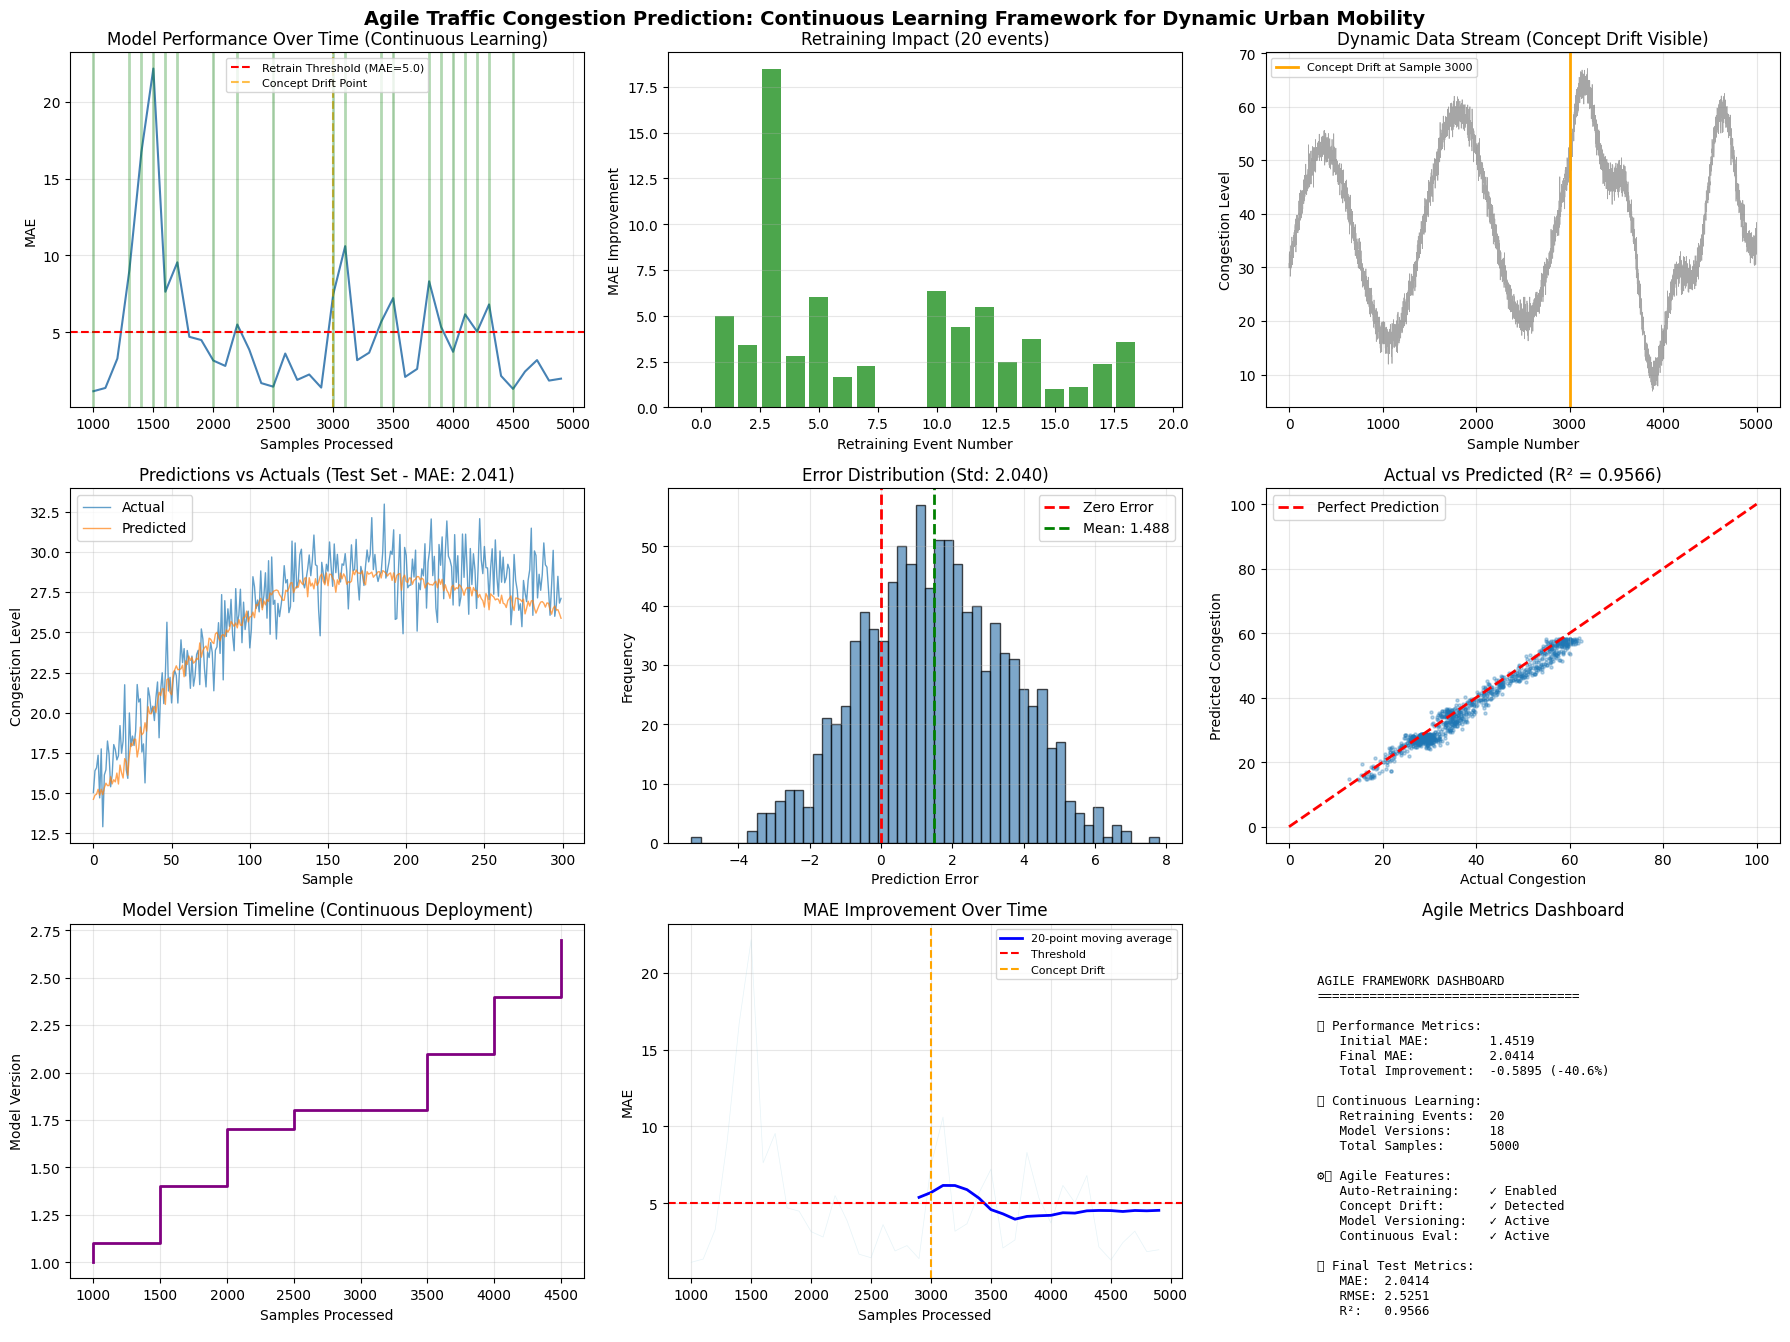

In [ ]:
# ============================================
# SECTION 8: VISUALIZATION DASHBOARD
# ============================================

import matplotlib.pyplot as plt
import pandas as pd

# Ensure config.concept_drift_point is defined for plotting
if not hasattr(config, 'concept_drift_point'):
    config.concept_drift_point = 3000 # Default value from generate_dynamic_traffic_stream

# Ensure stream_mae and sample_indices are defined, even if continuous learning loop wasn't run
if 'stream_mae' not in globals():
    stream_mae = []
if 'sample_indices' not in globals():
    sample_indices = []

fig = plt.figure(figsize=(18, 14))

# Plot 1: Model Performance Over Time
ax1 = fig.add_subplot(3, 3, 1)
if stream_mae and sample_indices:
    ax1.plot(sample_indices, stream_mae, linewidth=1.5, color='steelblue')
    ax1.axhline(y=config.retraining_threshold_mae, color='r', linestyle='--', label=f'Retrain Threshold (MAE={config.retraining_threshold_mae})')
    ax1.axvline(x=config.concept_drift_point, color='orange', linestyle='--', label='Concept Drift Point', alpha=0.7)
    for retrain in manager.retraining_log:
        ax1.axvline(x=retrain['sample'], color='g', alpha=0.3, linewidth=2)
    ax1.set_xlabel('Samples Processed')
    ax1.set_ylabel('MAE')
    ax1.set_title('Model Performance Over Time (Continuous Learning)')
    ax1.legend(fontsize=8)
    ax1.grid(True, alpha=0.3)
else:
    ax1.text(0.5, 0.5, 'Continuous learning data not available.\nRun Section 6 first.', ha='center', va='center', transform=ax1.transAxes)
    ax1.set_title('Model Performance Over Time')

# Plot 2: Retraining Impact
ax2 = fig.add_subplot(3, 3, 2)
if manager.retraining_log:
    retrain_df = pd.DataFrame(manager.retraining_log)
    colors = ['green' if x > 0 else 'red' for x in retrain_df['improvement']]
    ax2.bar(range(len(retrain_df)), retrain_df['improvement'], color=colors, alpha=0.7)
    ax2.axhline(y=0, color='black', linewidth=0.5)
    ax2.set_xlabel('Retraining Event Number')
    ax2.set_ylabel('MAE Improvement')
    ax2.set_title(f'Retraining Impact ({len(manager.retraining_log)} events)')
    ax2.grid(True, alpha=0.3, axis='y')
else:
    ax2.text(0.5, 0.5, 'No retraining events\ntriggered', ha='center', va='center', transform=ax2.transAxes)
    ax2.set_title('Retraining Impact')

# Plot 3: Data Stream with Concept Drift
ax3 = fig.add_subplot(3, 3, 3)
ax3.plot(targets, linewidth=0.5, alpha=0.7, color='gray')
ax3.axvline(x=config.concept_drift_point, color='orange', linewidth=2, label=f'Concept Drift at Sample {config.concept_drift_point}')
ax3.set_xlabel('Sample Number')
ax3.set_ylabel('Congestion Level')
ax3.set_title('Dynamic Data Stream (Concept Drift Visible)')
ax3.legend(fontsize=8)
ax3.grid(True, alpha=0.3)

# Plot 4: Predictions vs Actuals (Test Set)
ax4 = fig.add_subplot(3, 3, 4)
with torch.no_grad():
    test_predictions = manager.active_model(X_test).numpy().flatten()
test_actuals = y_test.numpy()
sample_display = min(300, len(test_predictions))
ax4.plot(test_actuals[:sample_display], label='Actual', alpha=0.7, linewidth=1)
ax4.plot(test_predictions[:sample_display], label='Predicted', alpha=0.7, linewidth=1)
ax4.set_xlabel('Sample')
ax4.set_ylabel('Congestion Level')
ax4.set_title(f'Predictions vs Actuals (Test Set - MAE: {final_metrics["mae"]:.3f})')
ax4.legend()
ax4.grid(True, alpha=0.3)

# Plot 5: Error Distribution
ax5 = fig.add_subplot(3, 3, 5)
errors = test_actuals - test_predictions
ax5.hist(errors, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
ax5.axvline(x=0, color='r', linestyle='--', linewidth=2, label='Zero Error')
ax5.axvline(x=np.mean(errors), color='g', linestyle='--', linewidth=2, label=f'Mean: {np.mean(errors):.3f}')
ax5.set_xlabel('Prediction Error')
ax5.set_ylabel('Frequency')
ax5.set_title(f'Error Distribution (Std: {np.std(errors):.3f})')
ax5.legend()
ax5.grid(True, alpha=0.3)

# Plot 6: Scatter Plot (Actual vs Predicted)
ax6 = fig.add_subplot(3, 3, 6)
ax6.scatter(test_actuals, test_predictions, alpha=0.3, s=5)
ax6.plot([0, 100], [0, 100], 'r--', linewidth=2, label='Perfect Prediction')
ax6.set_xlabel('Actual Congestion')
ax6.set_ylabel('Predicted Congestion')
ax6.set_title(f'Actual vs Predicted (R² = {final_metrics["r2"]:.4f})')
ax6.legend()
ax6.grid(True, alpha=0.3)

# Plot 7: Model Version Timeline
ax7 = fig.add_subplot(3, 3, 7)
if manager.performance_log:
    versions = [log['version'] for log in manager.performance_log]
    # Extract numerical part of version (e.g., '1.0' from 'Model_1.0_vYYYYMMDDHHMMSS_1.0')
    version_numbers = [float(v.split('_')[-1]) if '_' in v else float(v) for v in versions]
    samples = [log['sample'] for log in manager.performance_log]
    ax7.step(samples, version_numbers, where='post', linewidth=2, color='purple')
    ax7.set_xlabel('Samples Processed')
    ax7.set_ylabel('Model Version')
    ax7.set_title('Model Version Timeline (Continuous Deployment)')
    ax7.grid(True, alpha=0.3)
else:
    ax7.text(0.5, 0.5, 'Performance log not available.', ha='center', va='center', transform=ax7.transAxes)
    ax7.set_title('Model Version Timeline')

# Plot 8: Improvement Over Time
ax8 = fig.add_subplot(3, 3, 8)
window_size = 20
if stream_mae and sample_indices and len(stream_mae) > window_size:
    smoothed_mae = pd.Series(stream_mae).rolling(window=window_size).mean()
    ax8.plot(sample_indices, stream_mae, alpha=0.3, color='lightblue', linewidth=0.5)
    ax8.plot(sample_indices, smoothed_mae, color='blue', linewidth=2, label=f'{window_size}-point moving average')
    ax8.axhline(y=config.retraining_threshold_mae, color='r', linestyle='--', label='Threshold')
    ax8.axvline(x=config.concept_drift_point, color='orange', linestyle='--', label='Concept Drift')
    ax8.set_xlabel('Samples Processed')
    ax8.set_ylabel('MAE')
    ax8.set_title('MAE Improvement Over Time')
    ax8.legend(fontsize=8)
    ax8.grid(True, alpha=0.3)
else:
    ax8.text(0.5, 0.5, 'Continuous learning data not available\nor insufficient for smoothing.\nRun Section 6 first.', ha='center', va='center', transform=ax8.transAxes)
    ax8.set_title('MAE Improvement Over Time')

# Plot 9: Agile Metrics Dashboard
ax9 = fig.add_subplot(3, 3, 9)
metrics_text = f"""
AGILE FRAMEWORK DASHBOARD
{'=' * 35}

📊 Performance Metrics:
   Initial MAE:        {initial_mae:.4f}
   Final MAE:          {final_metrics['mae']:.4f}
   Total Improvement:  {improvement:.4f} ({improvement_pct:.1f}%)

🔄 Continuous Learning:
   Retraining Events:  {len(manager.retraining_log)}
   Model Versions:     {len(set([log['version'] for log in manager.retraining_log])) + 1 if manager.retraining_log else 1}
   Total Samples:      {manager.samples_processed}

⚙️ Agile Features:
   Auto-Retraining:    ✓ Enabled
   Concept Drift:      ✓ Detected
   Model Versioning:   ✓ Active
   Continuous Eval:    ✓ Active

🎯 Final Test Metrics:
   MAE:  {final_metrics['mae']:.4f}
   RMSE: {final_metrics['rmse']:.4f}
   R²:   {final_metrics['r2']:.4f}
"""

ax9.text(0.1, 0.9, metrics_text, transform=ax9.transAxes, fontsize=9, verticalalignment='top', family='monospace')
ax9.axis('off')
ax9.set_title('Agile Metrics Dashboard')

plt.suptitle('Agile Traffic Congestion Prediction: Continuous Learning Framework for Dynamic Urban Mobility', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('agile_framework_complete_results.png', dpi=150, bbox_inches='tight')
plt.show()